In [1]:
import os
import sys
import numpy as np
from pathlib import Path
from datetime import datetime, timedelta, timezone

from Legacy.Binance_new import Binance # Get_Price_Data_By_Time

# import importlib
# import RL_Trade_POC_Util

# # Reload the module
# importlib.reload(RL_Trade_POC_Util)

from RL_Trade_POC_Util import normalize, get_level, get_change, get_volatility, plot_array, plot_array1, plot_arrays

In [2]:
bn = Binance.instantiate(connect=False)

Initializing Binance singleton...


In [3]:
# Get_Price_Data_By_Time function seamlessly collects/creates price candles from Binance.
datatype = "klines" # "aggTrades" #, "klines"
symbol = "BTCUSDT"      # Any pair listed on Binance.

# dates that worked
# start = datetime(2018, 1, 1)    # Any datetime. Note Binance started operation in July 2017.
# end = datetime(2026, 3, 26) # + timedelta(minutes=100)     # Any datetime

start = datetime(2024, 1, 1)    # Any datetime. Note Binance started operation in July 2017.
end = datetime(2026, 2, 26) # + timedelta(minutes=100)     # Any datetime

interval = '1m'    # in '1m', '3m', '5m', '15m', '30m', '1h', '2h', '4h', '6h', '8h', '12h', '1d'.  (excludes: '3d', '1w')
print(f"interval: {interval}")
#------------------------------------------------------------------------------------------------------------------
candles, nFills, successful, _, reason = bn.Get_Price_Data_By_Time(datatype, symbol, interval, start, end)
print(reason)
if successful:          # price is a numpy array.
    print("\n Successful !!!!!!!!!! (nCandles, nAttributes) = {}, nCreated = {}".format(candles.shape, nFills))

interval: 1m
nCreated/nTotal/expected 0/1133280/1133280. 
Returning 10 columns: O H L C V, Quote V, nTrades, Buy base V, Buy quote V, Mark (0: original not forged)


 Successful !!!!!!!!!! (nCandles, nAttributes) = (1133280, 10), nCreated = 0


In [4]:
marks = candles[:, 9]
z_marks = marks[marks == 0]
print(len(marks), len(z_marks), len(marks) -  len(z_marks))

1133280 1133280 0


In [5]:
n = 500

x = candles[:n, 3]      # close
v = candles[:n, 4]      # volume
x_normal = normalize(x, axis=0) * 2
v_normal = normalize(v, axis=0) * 2
lookback = 30           # we look lookback as far as 'lookback'

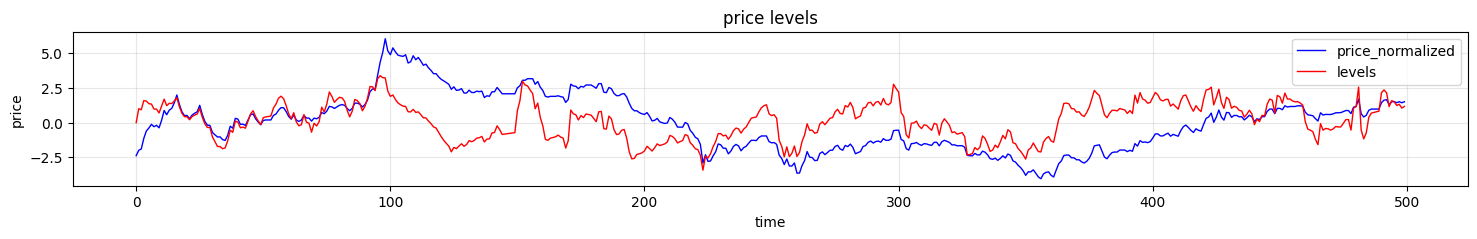

In [6]:

levels = []
for anchor in range(x.shape[0]):
    level = get_level(x, anchor, lookback, axis=0)
    levels.append(level)
levels = np.array(levels)
assert levels.shape == x.shape

plot_arrays([x_normal, levels], labels=['price_normalized', 'levels'], title="price levels", xlabel="time", ylabel="price", figsize=(18, 2), flip=False, save_path=None)

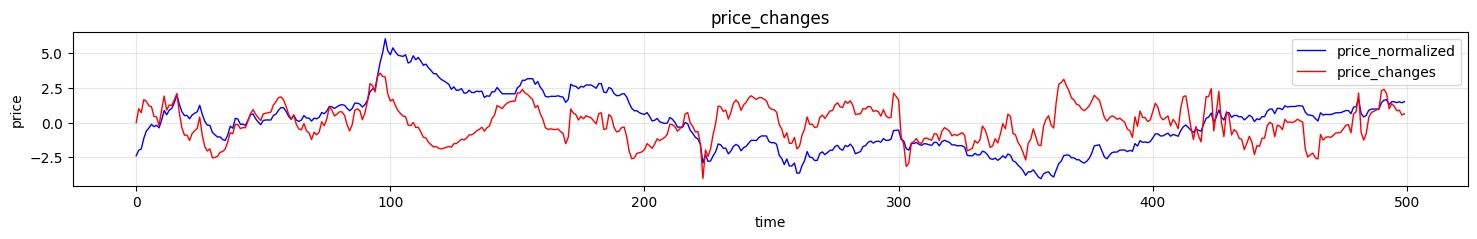

In [7]:
price_changes = []
for anchor in range(x.shape[0]):
    pc = get_change(x, anchor, lookback, axis=0)
    price_changes.append(pc)
price_changes = np.array(price_changes)
assert price_changes.shape == x.shape

plot_arrays([x_normal, price_changes], labels=['price_normalized', 'price_changes'], title="price_changes", xlabel="time", ylabel="price", figsize=(18, 2), flip=False, save_path=None)


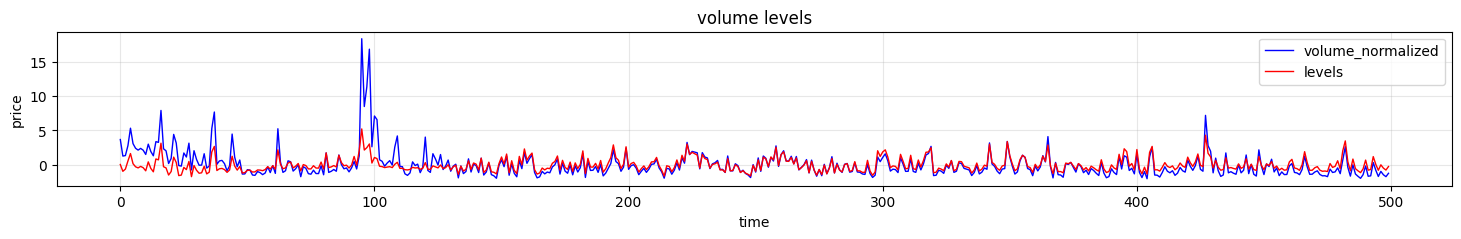

In [8]:
levels = []
for anchor in range(x.shape[0]):
    level = get_level(v, anchor, lookback, axis=0)
    levels.append(level)
levels = np.array(levels)
assert levels.shape == x.shape

plot_arrays([v_normal, levels], labels=['volume_normalized', 'levels'], title="volume levels", xlabel="time", ylabel="price", figsize=(18, 2), flip=False, save_path=None)

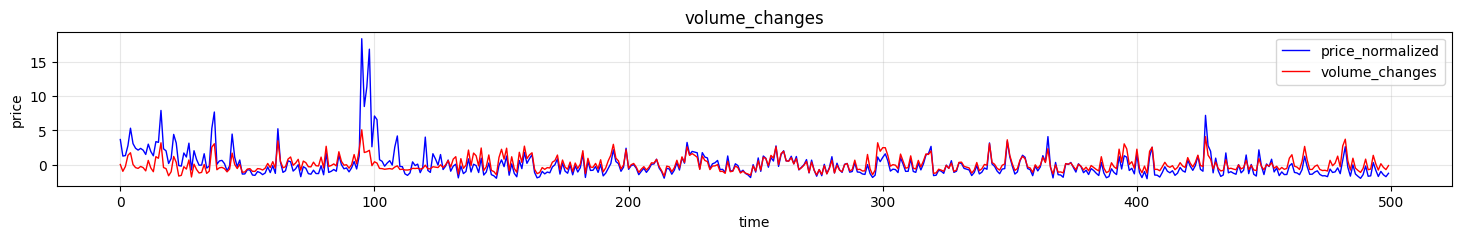

In [9]:
volume_changes = []
for anchor in range(v.shape[0]):
    vc = get_change(v, anchor, lookback, axis=0)
    volume_changes.append(vc)
volume_changes = np.array(volume_changes)
assert volume_changes.shape == v.shape

plot_arrays([v_normal, volume_changes], labels=['price_normalized', 'volume_changes'], title="volume_changes", xlabel="time", ylabel="price", figsize=(18, 2), flip=False, save_path=None)


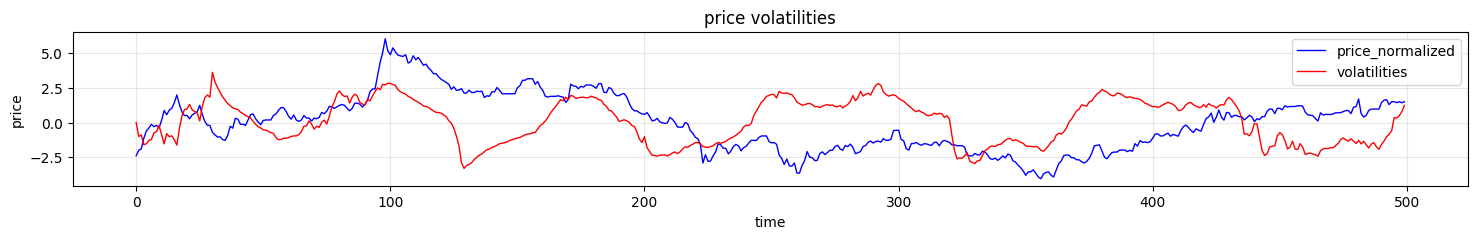

In [10]:
volatilities = []
for anchor in range(x.shape[0]):
    volatility = get_volatility(x, anchor, lookback, axis=0, span=lookback)
    volatilities.append(volatility)
volatilities = np.array(volatilities)
assert volatilities.shape == x.shape

plot_arrays([x_normal, volatilities], labels=['price_normalized', 'volatilities'], title="price volatilities", xlabel="time", ylabel="price", figsize=(18, 2), flip=False, save_path=None)


In [11]:
from enum import Enum
import torch
import torch.nn as nn
import torch.nn.functional as F

class Action(Enum):
    Buy = -1
    Hold = 0
    Sell = 1
    
max_buys = 30
max_price_history = 300
state_features = max_price_history + 5 + max_buys
print(f"state_features {state_features}")
    
def get_reward(action, price_curr, buy_costs):
    would_sell_revenue = len(buy_costs) * price_curr
    total_cost = sum(buy_costs)
    would_sell_profit = would_sell_revenue - total_cost
    # print(f"would_sell_profit {would_sell_profit}")
    sell_reward = -1 if len(buy_costs) == 0 else (-1 if would_sell_profit <= 0 else 1)      # -1 if would_sell_profit <= 0 ---- think of fees
    dict = { Action.Buy: 0, Action.Hold: 0, Action.Sell: sell_reward}
    reward = dict[action]
    return reward

def get_state_tensor(prices, volumes, buy_costs):
    state = prices[- max_price_history :].tolist()     #----------------------- Consider introducing compressed history. No need to flip.
    assert len(state) == max_price_history
    state.append(get_level(prices, len(prices)-1, lookback, axis=0))
    state.append(get_change(prices, len(prices)-1, lookback, axis=0))
    state.append(get_level(volumes, len(prices)-1, lookback, axis=0))
    state.append(get_change(volumes, len(prices)-1, lookback, axis=0))
    state.append(get_volatility(prices, len(prices)-1, lookback, span=lookback))
    assert len(buy_costs) <= max_buys
    state = state + buy_costs + [0 for _ in range(max_buys - len(buy_costs))]
    state = torch.tensor(state)
    assert state.shape[-1] == state_features
    state = state.unsqueeze(0)  # (batch, state_features)
    return state

def take_action(action, prices, volumes, buy_costs, buy_unit=1):
    price_curr = prices[-1]
    reward = get_reward(action, price_curr, buy_costs)
    state = get_state_tensor(prices, volumes, buy_costs)
    done = action == Action.Sell

    cash_in, cash_out = 0, 0
    if action == Action.Buy:
        if len(buy_costs) < max_buys:
            cash_out += price_curr * buy_unit
            buy_costs.append(cash_out)
    elif action == Action.Sell:
        cash_in += len(buy_costs) * buy_unit * price_curr
        buy_costs = []
    
    assert cash_in <= 0 or cash_out <= 0
    net_cash_in = cash_in - cash_out
    
    state_next = get_state_tensor(prices, volumes, buy_costs)
    
    return state_next, reward, done, buy_costs, net_cash_in

state_features 335


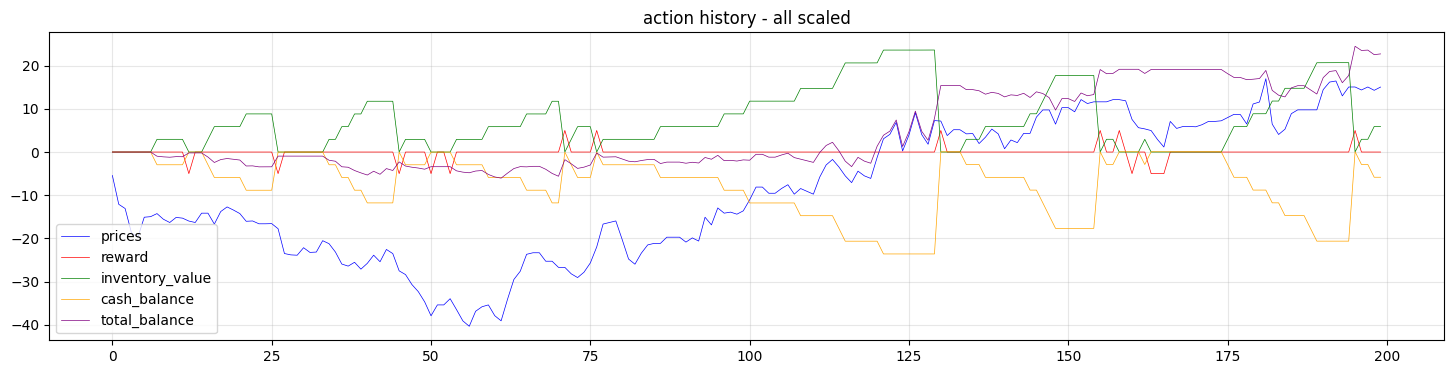

In [12]:
import random

buy_costs = []
actions = [Action.Buy] * 3 + [Action.Hold] * 10 + [Action.Sell] * 1

reward_history = []
inventory_value_history = []
cash_balance_history, cash_balance = [], 0

ext_lookback = max(3 * lookback - 2, max_price_history)     # max_price_history: tight

for anchor in range(len(x)):  
    if anchor < ext_lookback: continue
    
    action = random.choice(actions)
    prices = x [anchor - ext_lookback + 1 : anchor + 1]
    volumes = v [anchor - ext_lookback + 1 : anchor + 1]
    
    price_curr = prices[-1]
    state, reward, done, buy_costs, net_cash_in = take_action(action, prices, volumes, buy_costs)
    reward_history.append(reward)
    inventory_value_history.append(len(buy_costs)*price_curr)
    cash_balance += net_cash_in
    cash_balance_history.append(cash_balance)
    
    # print(action, f"reward/cash_in/balance {reward}/{net_cash_in}/{cash_balance} {'positive' if cash_balance > 0 else 'nagative'}")

cash_balance_history = np.array(cash_balance_history)
cash_balance_history = cash_balance_history / cash_balance_history.std() * 7

inventory_value_history = np.array(inventory_value_history)
inventory_value_history = inventory_value_history/inventory_value_history.std() * 7

total_balance_history = (cash_balance_history + inventory_value_history) * 300
    
arrays = [x_normal[ext_lookback : ] * 10, np.array(reward_history) * 5, inventory_value_history, cash_balance_history, total_balance_history]
labels = ['prices', 'reward', 'inventory_value', 'cash_balance', 'total_balance']
length = len(x_normal[ext_lookback : ])
for arr in arrays: assert len(arr) == length
plot_arrays(arrays, labels, title="action history - all scaled", xlabel="", ylabel="", figsize=(18, 4), flip=False, lw=0.5)

In [13]:

class PositionwiseFeedForward(nn.Module):
    def __init__(self, in_features, hidden_features=None, out_features=None, 
                 act_layer=nn.GELU, drop=0., depth=1):
        
        super().__init__()
        out_features = out_features or in_features
        hidden_features = hidden_features or in_features
        
        layers = []
        
        # First layer: input to hidden
        layers.append(nn.Linear(in_features, hidden_features))
        layers.append(act_layer())
        layers.append(nn.Dropout(drop))
        
        # Intermediate hidden layers (if depth > 1)
        for _ in range(depth - 1):
            layers.append(nn.Linear(hidden_features, hidden_features))
            layers.append(act_layer())
            layers.append(nn.Dropout(drop))
        
        # Final layer: hidden to output
        layers.append(nn.Linear(hidden_features, out_features))
        
        self.net = nn.Sequential(*layers)
        
    def forward(self, x, ss=None):
        return self.net(x)
    
class ActionValue(nn.Module):
    def __init__(self, state_features, hidden_features, nAcitons, depth=1):
        super().__init__()
        self.ffn = PositionwiseFeedForward(state_features, hidden_features, out_features=nAcitons, act_layer=nn.GELU, depth=depth)
        
    def forward(self, state):
        ffn_out = self.ffn(state)      # scaled for faster training. expected value in {-1, +1}
        return ffn_out

Q_model = ActionValue(20, 50, 3, 2)
state = torch.tensor([1.2] * 20).unsqueeze(0)
with torch.set_grad_enabled(False):
    q = Q_model(state).squeeze(0)
print(q)

tensor([0.1393, 0.0610, 0.0879])


In [ ]:
import random
import torch
import numpy as np
from collections import deque

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

action_list = list(Action)

# Initialize Q-network and Target network
Q_model = ActionValue(state_features, hidden_features=state_features * 4, 
                      nAcitons=len(action_list), depth=7).to(device)
old_Q_model = ActionValue(state_features, hidden_features=state_features * 4,
                       nAcitons=len(action_list), depth=7).to(device)

# Initialize target network with same weights
old_Q_model.load_state_dict(Q_model.state_dict())
old_Q_model.eval()  # Target network in evaluation mode

def train(nEpochs, epsilon, gamma, batch_size, target_update_freq=100, buy_unit=1, bi_net=False):
    
    # Learning rate - alpha is handled by optimizer, not in update rule
    optimizer = torch.optim.AdamW(Q_model.parameters(), lr=1e-4)
    
    # Use deque for efficient memory
    step_memory = deque(maxlen=10000)
    # Attempt vector = (10, 80, 10) - As much Sell as Buy, mostly Hold.
    action_distribution = [Action.Buy] * 10 + [Action.Hold] * 80 + [Action.Sell] * 10
    
    close_idx, volume_idx, mark_idx = 3, 4, 9   # Decided by Binance_new.py
    env_len = len(candles[:, close_idx])
    forget_len = np.count_nonzero(candles[:, mark_idx]) # Forged candles are marked non-zero
    print(f"forged/total: {forget_len}/{env_len}")

    normal_prices = candles[:, close_idx]       # closing prices, as is.
    normal_volumes = candles[:, volume_idx]     # volumes, as is.
    
    losses, net_cashes_in, total_cash = [], [], 0
    step_count = 0
    
    for epoch in range(nEpochs):
        epoch_epsilon = max(epsilon * (1 - epoch / nEpochs), 0.05)
        
        epoch_work_span = 300
        #-------------- Pick up the anchor of epoch -------------------
        while True:
            epoch_anchor = random.randint(ext_lookback, env_len - epoch_work_span)
            candlespace = range(epoch_anchor - ext_lookback, epoch_anchor + epoch_work_span)
            if (candles[candlespace, mark_idx]==0).all():
                break
            print(f"Found forged candles. picking another..........................................")

        running_anchor = epoch_anchor

        buy_costs = []
        prices = normal_prices[running_anchor - ext_lookback : running_anchor + 1]
        volumes = normal_volumes[running_anchor - ext_lookback : running_anchor + 1]
        state = get_state_tensor(prices, volumes, buy_costs).to(device)
        
        buy_actions, hold_actions = 0, 0
        
        done = False
        nActions = 0
        
        # action_distribution = [Action.Buy] * 10 + [Action.Hold] * 50 + [Action.Sell] * 2
        action_distribution = [Action.Buy, Action.Hold, Action.Sell]
        
        while not done and running_anchor < epoch_anchor + epoch_work_span:
            
            #------------- Action selection (epsilon-greedy) ---------------
            with torch.no_grad():
                q_values = Q_model(state)
                best_action_idx = torch.argmax(q_values[0]).item()
                best_action = action_list[best_action_idx]
            
            # Epsilon-greedy
            if random.random() < epoch_epsilon:
                action = random.choice(action_distribution)
            else:
                action = best_action
            
            # Take action
            running_anchor += 1
            prices = normal_prices[running_anchor - ext_lookback : running_anchor + 1]
            volumes = normal_volumes[running_anchor - ext_lookback : running_anchor + 1]
            state_next, reward, done, buy_costs, net_cash_in = take_action(action, prices, volumes, buy_costs, buy_unit=buy_unit)
            net_cashes_in.append(net_cash_in)
            total_cash += net_cash_in
            if len(net_cashes_in) > 1000:
                net_cashes_in = net_cashes_in[-1000:]
            state_next = state_next.to(device)
            
            if action == Action.Buy:
                buy_actions += 1
            elif action == Action.Hold:
                hold_actions += 1
            
            # Store experience (don't store Q-values, compute them during training)
            step_memory.append((state, action, reward, state_next, done))
            
            state = state_next
            nActions += 1
            
            #-------------- Training ----------
            if len(step_memory) >= batch_size:
                # Sample mini-batch
                batch = random.sample(step_memory, batch_size)
                
                states_batch = []
                actions_batch = []
                rewards_batch = []
                next_states_batch = []
                dones_batch = []

                for s, a, r, s_next, d in batch:
                    # Flatten to (state_features,) if it's (1, state_features)
                    if s.dim() == 2 and s.shape[0] == 1:
                        s = s.squeeze(0)  # Remove batch dimension
                    if s_next.dim() == 2 and s_next.shape[0] == 1:
                        s_next = s_next.squeeze(0)
                    
                    states_batch.append(s)
                    actions_batch.append(action_list.index(a))
                    rewards_batch.append(r)
                    next_states_batch.append(s_next)
                    dones_batch.append(d)

                # Stack to create batch dimension
                states_batch = torch.stack(states_batch, dim=0).to(device)  # (batch_size, state_features)
                actions_batch = torch.tensor(actions_batch, device=device).unsqueeze(1)
                rewards_batch = torch.tensor(rewards_batch, device=device).unsqueeze(1)
                next_states_batch = torch.stack(next_states_batch, dim=0).to(device)  # (batch_size, state_features)
                dones_batch = torch.tensor(dones_batch, device=device).unsqueeze(1)
                
                # Compute current Q values
                pred_q_s_a = Q_model(states_batch).gather(1, actions_batch)
                
                # Compute target Q values using TARGET network
                with torch.no_grad():
                    if bi_net:
                       q_next_s_max = old_Q_model(next_states_batch).max(1, keepdim=True)[0]
                    else:
                        q_next_s_max = Q_model(next_states_batch).max(1, keepdim=True)[0]       #------------- original ------------
                    
                    target_q_s_a = rewards_batch + gamma * q_next_s_max * (~dones_batch)  # Don't add if done
                
                # Compute loss
                loss = torch.nn.functional.mse_loss(pred_q_s_a, target_q_s_a)
                
                # Optimize
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(Q_model.parameters(), max_norm=1.0)
                optimizer.step()
                
                # Update target network
                step_count += 1
                if bi_net and step_count % target_update_freq == 0:
                    old_Q_model.load_state_dict(Q_model.state_dict())                      #------------- original -------------
                    print(f"Target network updated at step {step_count}")
                
                # Logging
                losses.append(loss.item())
                if len(losses) > 1000:
                    losses = losses[-1000:]
                
                if nActions % 10 == 0:
                    print(f"Epoch {epoch}, Step {nActions}, Loss: {loss.item():.6f}")
        
        # Print epoch summary
        if losses:
            ma_loss = sum(losses) / len(losses)
            ma_cash_in = sum(net_cashes_in) / len(net_cashes_in)
            print(f"Epoch {epoch}, Buy/Hold: {buy_actions}/{hold_actions}, MA Loss: {ma_loss:.5f}, MA Cash_in: {ma_cash_in:.5f}, total_cash: {total_cash:.2f}")

# Call the function
train(nEpochs=100000, epsilon=0.3, gamma=0.99, batch_size=32, target_update_freq=100, buy_unit=0.001, bi_net=True)

Using device: cuda


In [ ]:
import random
import torch
import numpy as np

# Check if GPU is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

action_list = list(Action)

Q_model = ActionValue(state_features, hidden_features=state_features * 4, nAcitons=len(action_list), depth=5).to(device)

def train(nEpochs, epsilon, gamma, batch_size, alpha):
    
    # FIXED: Use a reasonable learning rate
    trainable_params = [p for p in Q_model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(trainable_params, lr=1e-4)  # Changed from 1e-8
    
    step_memory, max_memory = [], batch_size * 5
    
    close_idx, volume_idx, mark_idx = 3, 4, 9
    env_len = len(candles[:, close_idx])
    forget_len = np.count_nonzero(candles[:, mark_idx])
    print(f"forged/total: {forget_len}/{env_len}")

    normal_prices = candles[:, close_idx]
    normal_volumes = candles[:, volume_idx]
    
    losses = []
    
    for epoch in range(nEpochs):
        epoch_epsilon = max(epsilon * (1 - epoch / nEpochs), 0.05)
        
        epoch_work_span = 300
        #-------------- Pick up the anchor of epoch -------------------
        while True:
            epoch_anchor = random.randint(ext_lookback, env_len - epoch_work_span)
            candlespace = range(epoch_anchor - ext_lookback, epoch_anchor + epoch_work_span)
            if np.abs(candles[candlespace, mark_idx]).min() <= 0:
                break
            print(f"Found forged candles. picking another..........................................")

        running_anchor = epoch_anchor

        buy_costs = []
        prices = normal_prices[running_anchor - ext_lookback : running_anchor + 1]
        volumes = normal_volumes[running_anchor - ext_lookback : running_anchor + 1]
        state = get_state_tensor(prices, volumes, buy_costs).to(device)  # Already on correct device
        
        buy_actions, hold_actions = 0, 0
        
        done = False
        nActions = 0
        
        while not done and running_anchor < epoch_anchor + epoch_work_span:
            
            #------------- pick-up <action, Q_state_action> ---------------
            r = random.randint(1, 100)
            random_action = Action.Buy if r <= 30 else Action.Hold if r <= 90 else Action.Sell
            
            # FIXED: Ensure state has batch dimension
            with torch.no_grad():  # Don't track gradients for action selection
                q_values = Q_model(state.unsqueeze(0) if state.dim() == 1 else state)[0]
                argmax = torch.argmax(q_values)
                best_action = action_list[argmax.item()]
            
            action = random_action if random.randint(1, 100) < epoch_epsilon * 100 else best_action
            action_idx = action_list.index(action)
            
            # Get Q_state_action with gradient tracking for learning
            q_values_with_grad = Q_model(state.unsqueeze(0) if state.dim() == 1 else state)[0]
            Q_state_action = q_values_with_grad[action_idx]
            
            if action == Action.Buy:
                buy_actions += 1
            elif action == Action.Hold:
                hold_actions += 1
 
            #-------------- take action to get <reward, state_next> ----------
            running_anchor += 1
            prices = normal_prices[running_anchor - ext_lookback : running_anchor + 1]
            volumes = normal_volumes[running_anchor - ext_lookback : running_anchor + 1]
            state_next, reward, done, buy_costs, _ = take_action(action, prices, volumes, buy_costs)
            state_next = state_next.to(device)

            #-------------- get <max_a_Q_state_next> with no grad ----------
            with torch.no_grad():
                q_values_next = Q_model(state_next.unsqueeze(0) if state_next.dim() == 1 else state_next)[0]
                maxQ_state_next_a = q_values_next.max()

            #-------------- save in step_memory ----------
            step_memory.append((state, action, Q_state_action, reward, maxQ_state_next_a, done))
            step_memory = step_memory[-max_memory:]
            state = state_next
            nActions += 1
            
            #-------------- sample mini-batch and train ----------
            if len(step_memory) >= batch_size:
                sample_experiences = random.sample(step_memory, batch_size)
                
                #-------------- prepare batch (FIXED: all on correct device) ----------
                states_list, action_indices_list, target_values_list = [], [], []
                
                for mem_state, mem_action, mem_Q_state_action, mem_reward, mem_maxQ_next, mem_done in sample_experiences:
                    # FIXED: Compute target without .item() and with proper device
                    target = mem_Q_state_action + alpha * (mem_reward + gamma * mem_maxQ_next - mem_Q_state_action)
                    
                    # FIXED: Detach target - no gradients needed
                    target = target.detach().view(1)  # Shape (1,)
                    
                    action_idx = torch.tensor([action_list.index(mem_action)], dtype=torch.long, device=device)
                    
                    # FIXED: Ensure state has batch dimension
                    if mem_state.dim() == 1:
                        mem_state = mem_state.unsqueeze(0)
                    
                    states_list.append(mem_state)
                    action_indices_list.append(action_idx)
                    target_values_list.append(target)
                
                # Stack all batch elements
                states_batch = torch.cat(states_list, dim=0).to(device)
                action_indices_batch = torch.stack(action_indices_list, dim=0).to(device)
                target_values_batch = torch.stack(target_values_list, dim=0).to(device)
                
                #-------------- training step ----------
                Q_model.train()
                optimizer.zero_grad()
                
                q_values_batch = Q_model(states_batch)
                Q_state_actions_pred = q_values_batch.gather(1, action_indices_batch)
                
                # FIXED: MSE loss is more stable than sqrt(MSE)
                loss = torch.nn.functional.mse_loss(Q_state_actions_pred, target_values_batch)
                
                loss.backward()
                
                # FIXED: Gradient clipping for stability
                torch.nn.utils.clip_grad_norm_(Q_model.parameters(), max_norm=1.0)
                
                optimizer.step()
                
                # FIXED: Detach loss value for logging
                losses.append(loss.detach().item())
                
                if nActions % 10 == 0:
                    print(f"Epoch {epoch}, Step {nActions}, Loss: {loss.item():.6f}")
        
        # Keep only recent losses for moving average
        losses = losses[-1000:]
        if losses:
            ma_loss = sum(losses) / len(losses)
            print(f"Epoch {epoch}, Buy: {buy_actions}, Hold: {hold_actions}, MA Loss: {ma_loss:.6f}")

In [ ]:
train(nEpochs=100000, epsilon=0.9, gamma=1, batch_size=32, alpha=0.3)
print(f"Done")